# De-risk 01 — Field NDVI time series from Sentinel-2

**Goal (plan Section 14, step 3):** prove the single biggest technical risk for the whole
project. For an arbitrary field polygon, can we:

1. Define a Texas field,
2. Search the free **Earth Search STAC API** for Sentinel-2 L2A scenes over it,
3. Read **only the pixels inside the field** (windowed COG reads),
4. Mask clouds/shadows using the **scene-classification (SCL)** band,
5. Compute **NDVI** and plot a season-long health time series + a map?

No AWS account or credentials are needed — the data is public and read anonymously.

If this notebook runs end-to-end and produces a sensible NDVI curve, the hardest part of the
project (satellite data at scale) is de-risked and the rest of the roadmap is mostly plumbing.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio.features
from shapely.geometry import shape, mapping
from pystac_client import Client
import odc.stac

STAC_URL = "https://earth-search.aws.element84.com/v1"
COLLECTION = "sentinel-2-c1-l2a"

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIELDS_DIR = REPO / "data" / "fields"
DOCS_DIR = REPO / "docs"
FIELDS_DIR.mkdir(parents=True, exist_ok=True)
print("repo root:", REPO)

repo root: /Users/achalla/Desktop/Personal Projects/Agrismart 2.0


## 1. Define a Texas field

A ~800 m square near Plainview, Hale County, TX — heavy cotton/corn country on the Texas High
Plains, so we expect a strong seasonal NDVI signal. In the real app this polygon comes from the
user drawing on a map (Module A).

In [2]:
# Field centre and half-size in degrees (~0.004 deg lat ~= 440 m).
lon0, lat0 = -101.78, 34.12
d = 0.004
field_geojson = {
    "type": "Feature",
    "properties": {"name": "plainview-demo-field"},
    "geometry": {
        "type": "Polygon",
        "coordinates": [[
            [lon0 - d, lat0 - d],
            [lon0 + d, lat0 - d],
            [lon0 + d, lat0 + d],
            [lon0 - d, lat0 + d],
            [lon0 - d, lat0 - d],
        ]],
    },
}

field = gpd.GeoDataFrame.from_features([field_geojson], crs="EPSG:4326")
(FIELDS_DIR / "plainview_demo_field.geojson").write_text(json.dumps(field_geojson, indent=2))

# Area via an equal-area projection.
area_ha = field.to_crs("EPSG:6933").area.iloc[0] / 10_000
centroid = field.geometry.iloc[0].centroid
print(f"area: {area_ha:.1f} ha | centroid: ({centroid.y:.4f}, {centroid.x:.4f})")
field_geom = field.geometry.iloc[0]

area: 65.5 ha | centroid: (34.1200, -101.7800)


## 2. Search Earth Search for Sentinel-2 scenes

We query one growing season (Apr–Oct 2024) and keep scenes with < 60% scene-wide cloud cover.
Per-scene cloud masking (step 4) handles the rest.

In [3]:
client = Client.open(STAC_URL)
search = client.search(
    collections=[COLLECTION],
    intersects=mapping(field_geom),
    datetime="2024-04-01/2024-10-31",
    query={"eo:cloud_cover": {"lt": 60}},
)
items = list(search.items())
items = sorted(items, key=lambda it: it.datetime)
print(f"found {len(items)} scenes")
for it in items[:5]:
    print(f"  {it.datetime:%Y-%m-%d}  cloud={it.properties['eo:cloud_cover']:.0f}%  {it.id}")

/Users/achalla/Desktop/Personal Projects/Agrismart 2.0/.venv/lib/python3.11/site-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


found 136 scenes
  2024-04-01  cloud=57%  S2B_T14SKC_20240401T172614_L2A
  2024-04-01  cloud=53%  S2B_T13SGT_20240401T172614_L2A
  2024-04-04  cloud=0%  S2B_T14SKC_20240404T174056_L2A
  2024-04-04  cloud=0%  S2B_T13SGT_20240404T174056_L2A
  2024-04-06  cloud=0%  S2A_T14SKC_20240406T172953_L2A


## 3. Windowed read of only the field's pixels

`odc.stac.load` with `geopolygon=` reads only the COG window covering the field — not the full
110 km x 110 km tile. We pull **red (B04)**, **nir (B08)** for NDVI, and **scl** for the cloud
mask, resampled onto a common 10 m grid and grouped to one layer per solar day.

In [4]:
ds = odc.stac.load(
    items,
    bands=["red", "nir", "scl"],
    geopolygon=field_geom,
    resolution=10,
    groupby="solar_day",
    chunks={},  # load eagerly; the window is tiny
)
print(ds)
print("\ngrid:", ds.odc.geobox.shape, "| crs:", ds.odc.geobox.crs)

<xarray.Dataset> Size: 2MB
Dimensions:      (y: 92, x: 77, time: 68)
Coordinates:
  * y            (y) float64 736B 3.779e+06 3.779e+06 ... 3.779e+06 3.778e+06
  * x            (x) float64 616B 2.432e+05 2.432e+05 ... 2.44e+05 2.44e+05
    spatial_ref  int32 4B 32614
  * time         (time) datetime64[ns] 544B 2024-04-01T17:34:35.049000 ... 20...
Data variables:
    red          (time, y, x) uint16 963kB dask.array<chunksize=(1, 92, 77), meta=np.ndarray>
    nir          (time, y, x) uint16 963kB dask.array<chunksize=(1, 92, 77), meta=np.ndarray>
    scl          (time, y, x) uint8 482kB dask.array<chunksize=(1, 92, 77), meta=np.ndarray>

grid: Shape2d(x=77, y=92) | crs: PROJCRS["WGS 84 / UTM zone 14N",BASEGEOGCRS["WGS 84",ENSEMBLE["World Geodetic System 1984 ensemble",MEMBER["World Geodetic System 1984 (Transit)"],MEMBER["World Geodetic System 1984 (G730)"],MEMBER["World Geodetic System 1984 (G873)"],MEMBER["World Geodetic System 1984 (G1150)"],MEMBER["World Geodetic System 1984 (G167

## 4. Cloud mask (SCL) + NDVI

**SCL classes we drop:** 0 no-data, 1 saturated/defective, 3 cloud shadow, 8 cloud (medium),
9 cloud (high), 10 thin cirrus. We keep 4 vegetation, 5 bare soil, 6 water, 7 unclassified,
11 snow.

**Reflectance scaling:** Sentinel-2 processing baseline >= 04.00 stores surface reflectance as
`DN` with a BOA offset of -1000 and scale 1/10000, i.e. `reflectance = (DN - 1000) / 10000`.
The offset matters for NDVI (it does not cancel in the denominator), so we apply it explicitly.

We also rasterize the field polygon so stats use only pixels **inside** the field, not the whole
loaded window.

In [5]:
# Reflectance with BOA offset applied.
def to_reflectance(band):
    ref = (band.astype("float32") - 1000.0) / 10000.0
    return ref.where((ref >= 0) & (ref <= 1))

red = to_reflectance(ds["red"])
nir = to_reflectance(ds["nir"])

# Keep only clear-ground SCL classes.
DROP_SCL = [0, 1, 3, 8, 9, 10]
clear = ~ds["scl"].isin(DROP_SCL)

ndvi = (nir - red) / (nir + red)
ndvi = ndvi.where(clear)

# Rasterize the field polygon onto the load grid -> only in-field pixels count.
gb = ds.odc.geobox
field_proj = field.to_crs(gb.crs)
field_mask = rasterio.features.geometry_mask(
    [mapping(field_proj.geometry.iloc[0])],
    out_shape=gb.shape,
    transform=gb.transform,
    invert=True,  # True == inside the field
)
field_mask = ndvi.isel(time=0).copy(data=field_mask)
ndvi_field = ndvi.where(field_mask)
print("in-field pixels:", int(field_mask.sum()))

in-field pixels: 6554


In [6]:
# Per-scene stats over in-field, cloud-free pixels.
n_pixels = int(field_mask.sum())
valid_frac = ndvi_field.notnull().sum(dim=("y", "x")) / n_pixels

stats = pd.DataFrame({
    "date": pd.to_datetime(ndvi_field.time.values),
    "ndvi_mean": ndvi_field.mean(dim=("y", "x"), skipna=True).values,
    "ndvi_p10": ndvi_field.quantile(0.10, dim=("y", "x"), skipna=True).values,
    "ndvi_p90": ndvi_field.quantile(0.90, dim=("y", "x"), skipna=True).values,
    "clear_fraction": valid_frac.values,
})
# Keep only usefully clear scenes (>= 40% of the field visible).
clean = stats[stats["clear_fraction"] >= 0.40].dropna(subset=["ndvi_mean"]).reset_index(drop=True)
print(f"{len(stats)} scenes -> {len(clean)} usefully clear")
clean.head(10)

/Users/achalla/Desktop/Personal Projects/Agrismart 2.0/.venv/lib/python3.11/site-packages/rasterio/warp.py:344: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  _reproject(


68 scenes -> 62 usefully clear


,date,ndvi_mean,ndvi_p10,ndvi_p90,clear_fraction
0,2024-04-01 17:34:35.049,0.174574,0.134423,0.229630,1.000000
1,2024-04-04 17:44:29.641,0.195428,0.147334,0.264637,1.000000
2,2024-04-06 17:34:34.479,0.189481,0.147713,0.251205,1.000000
3,2024-04-11 17:34:36.434,0.206244,0.148454,0.292374,1.000000
4,2024-04-14 17:44:32.754,0.195231,0.140148,0.296380,0.677601
5,2024-04-16 17:34:39.120,0.208965,0.145139,0.315891,0.993897
6,2024-04-21 17:34:36.482,0.210234,0.120994,0.368216,1.000000
7,2024-04-26 17:34:38.476,0.228490,0.138921,0.389320,1.000000
8,2024-04-29 17:44:34.581,0.235973,0.128450,0.422360,1.000000
9,2024-05-01 17:34:36.334,0.225863,0.128079,0.393043,1.000000


## 5. Season-long NDVI time series

saved docs/derisk_ndvi_timeseries.png and .csv


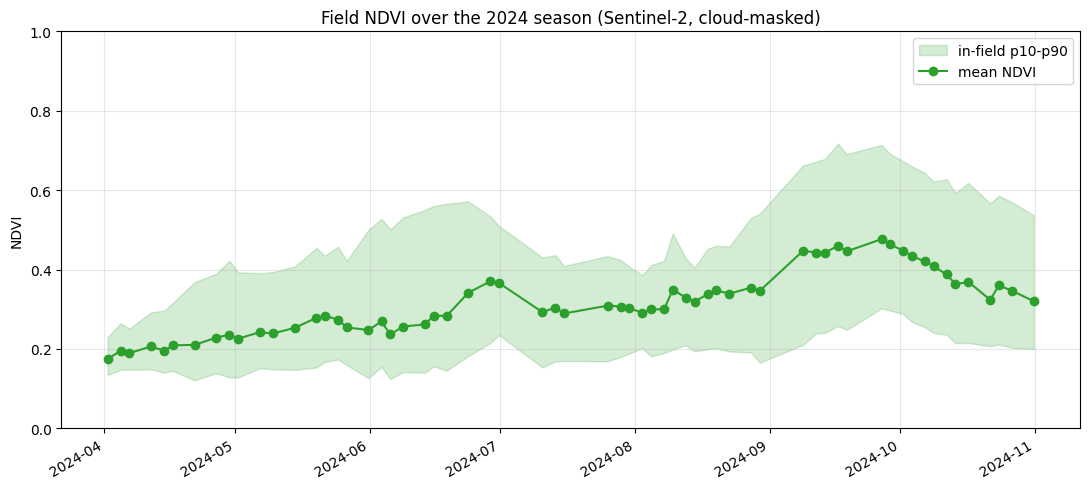

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(clean["date"], clean["ndvi_p10"], clean["ndvi_p90"],
                alpha=0.2, color="tab:green", label="in-field p10-p90")
ax.plot(clean["date"], clean["ndvi_mean"], "-o", color="tab:green", label="mean NDVI")
ax.set_title("Field NDVI over the 2024 season (Sentinel-2, cloud-masked)")
ax.set_ylabel("NDVI")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(DOCS_DIR / "derisk_ndvi_timeseries.png", dpi=130)
clean.to_csv(DOCS_DIR / "derisk_ndvi_timeseries.csv", index=False)
print("saved docs/derisk_ndvi_timeseries.png and .csv")

## 6. NDVI map for the greenest clear scene

saved docs/derisk_ndvi_map.png


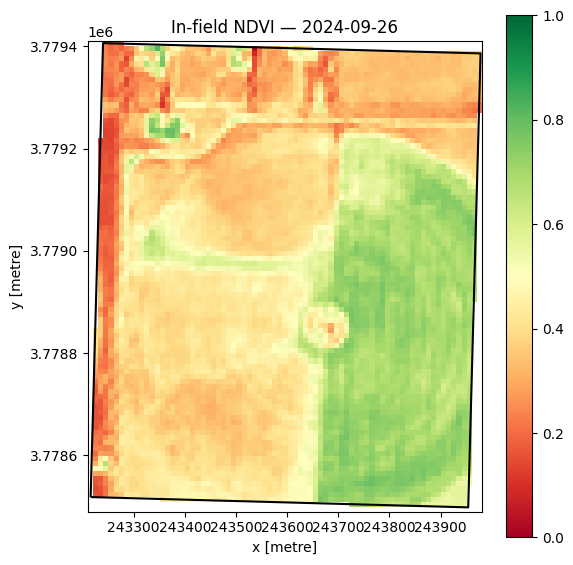

In [8]:
peak_date = clean.loc[clean["ndvi_mean"].idxmax(), "date"]
scene = ndvi_field.sel(time=peak_date, method="nearest")
fig, ax = plt.subplots(figsize=(6, 6))
im = scene.plot.imshow(ax=ax, cmap="RdYlGn", vmin=0, vmax=1, add_colorbar=True)
field_proj.boundary.plot(ax=ax, color="black", linewidth=1.5)
ax.set_title(f"In-field NDVI — {pd.to_datetime(peak_date):%Y-%m-%d}")
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(DOCS_DIR / "derisk_ndvi_map.png", dpi=130)
print("saved docs/derisk_ndvi_map.png")

## What this de-risks

If the curve above rises through summer and falls toward harvest, every hard piece of the
satellite story works on free, public data with no AWS account:

- STAC discovery of Sentinel-2 scenes over an arbitrary polygon,
- windowed COG reads (field pixels only, not whole tiles),
- SCL cloud/shadow masking,
- correct reflectance scaling and NDVI,
- per-field statistics ready to store (this is exactly Module C's per-scene output).

**Next:** wrap this logic into `pipelines/ingest/` as a reusable `process_scene(field, item)`
function, then drive it from Step Functions + Fargate for backfill (Phase 2).